# Computational Modeling of Tumor Growth and Treatment Dynamics

## Background
Mathematical oncology uses mathematical and computational methods to investigate cancer growth, progression, and treatment responses. This project explores simplified models of tumor growth and examines how different treatment parameters influence simulated tumor populations.

## Research Question
How do mathematical growth models, treatment intensity, treatment scheduling, and drug resistance influence simulated tumor population dynamics?

## Hypothesis
Increasing treatment intensity and duration will reduce simulated tumor burden, while treatment interruptions and drug resistance may contribute to tumor regrowth.

## Tools
Python, NumPy, SciPy, Matplotlib, Google Colab, and ordinary differential equations.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
print("Colab works!", np.__version__)

Colab works! 2.4.6


Exponential Tumor Growth Cell

The exponential growth model assumes that tumor growth is proportional to the current tumor population without resource limitations. Different growth rates are compared to investigate their effects on tumor progression and doubling time.

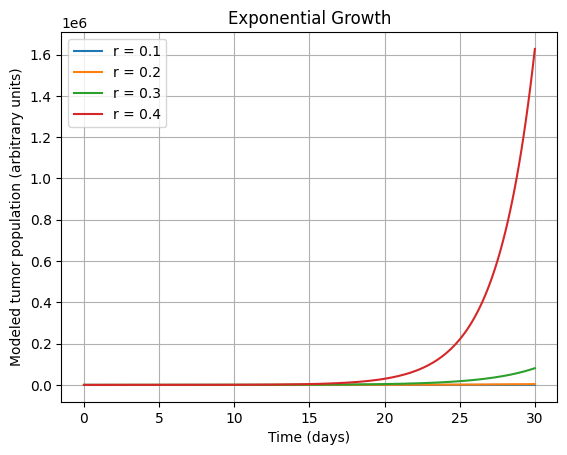

In [2]:
t = np.linspace(0, 30, 200)
N0 = 10
for r in [0.1, 0.2, 0.3, 0.4]:
    plt.plot(t, N0 * np.exp(r * t), label=f"r = {r}")
plt.xlabel("Time (days)")
plt.ylabel("Modeled tumor population (arbitrary units)")
plt.title("Exponential Growth")
plt.legend()
plt.grid(True)
plt.show()

Euler's Method and Numerical Solutions Cell

Euler's method approximates solutions to ordinary differential equations through incremental time steps. The numerical approximation is compared with the exact exponential growth solution to examine its accuracy.

In [3]:
ln2 = np.log(2)
for r in [0.2, 0.4]:
    print(f"r = {r}: doubling time = ln(2)/r = {ln2 / r:.2f} days")

r = 0.2: doubling time = ln(2)/r = 3.47 days
r = 0.4: doubling time = ln(2)/r = 1.73 days


Logistic and Gompertz Growth Models Cell

Unlike exponential growth, logistic and Gompertz models incorporate limitations on tumor population growth. Both models approach a carrying capacity, but they differ in how growth slows as the tumor population increases.

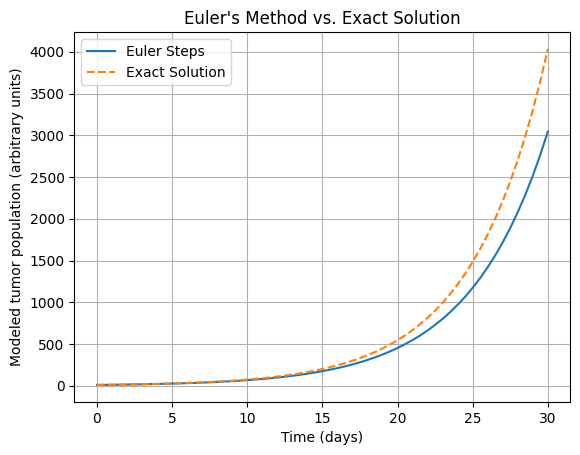

In [4]:
r, N0, dt = 0.2, 10, 0.5
t = dt * np.arange(61)
sizes = [N0]
for _ in t[1:]:
    size = sizes[-1]
    sizes.append(size + r * size * dt)
plt.plot(t, sizes, label="Euler Steps")
plt.plot(t, N0 * np.exp(r * t), "--", label="Exact Solution")
plt.xlabel("Time (days)")
plt.ylabel("Modeled tumor population (arbitrary units)")
plt.title("Euler's Method vs. Exact Solution")
plt.legend()
plt.grid(True)
plt.show()

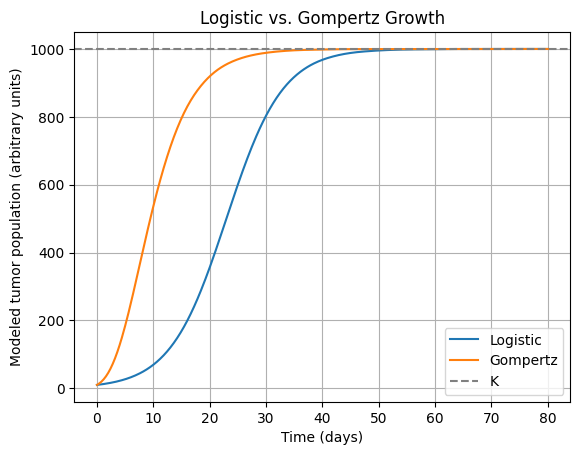

In [6]:
def logistic(t, N, r, K):
    return r * N * (1 - N / K)
def gompertz(t, N, r, K):
    return r * N * np.log(K / N)
t_eval = np.linspace(0, 80, 400)
for model, label in [(logistic, "Logistic"), (gompertz, "Gompertz")]:
    sol = solve_ivp(model, (0, 80), [10], args=(0.2, 1000), t_eval=t_eval)
    plt.plot(sol.t, sol.y[0], label=label)
plt.axhline(1000, linestyle="--", color="gray", label="K")
plt.xlabel("Time (days)")
plt.ylabel("Modeled tumor population (arbitrary units)")
plt.title("Logistic vs. Gompertz Growth")
plt.legend()
plt.grid(True)
plt.show()

Tumor Growth Rate Comparison Cell

The growth rates of the logistic and Gompertz models are compared across different tumor population sizes to investigate when each model reaches its maximum growth rate.

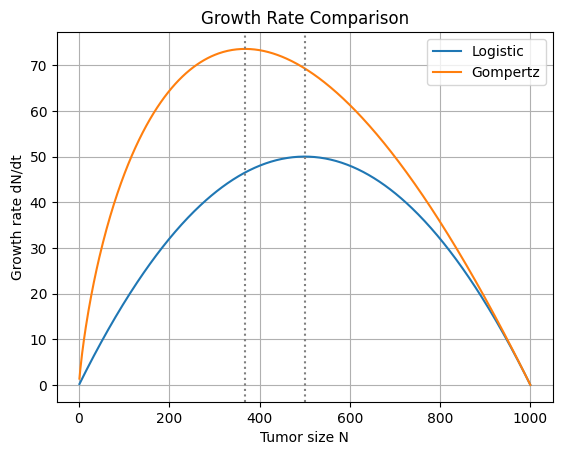

In [7]:
import numpy as np
import matplotlib.pyplot as plt

N = np.linspace(1, 1000, 500)

plt.plot(N, logistic(0, N, 0.2, 1000), label="Logistic")
plt.plot(N, gompertz(0, N, 0.2, 1000), label="Gompertz")

for peak in [500, 1000 / np.e]:
    plt.axvline(peak, linestyle=":", color="gray")

plt.xlabel("Tumor size N")
plt.ylabel("Growth rate dN/dt")
plt.title("Growth Rate Comparison")
plt.legend()
plt.grid(True)
plt.show()

Treatment vs. No Treatment Cell

A treatment-dependent death term is incorporated into the logistic growth model. Treated and untreated tumor populations are compared to investigate the effects of treatment and subsequent tumor regrowth.

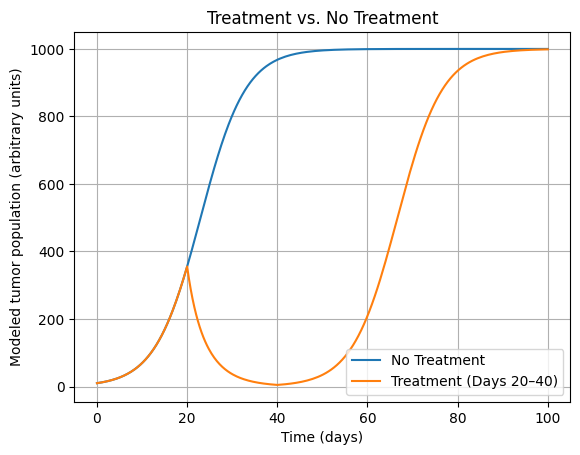

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

def simulate_treatment(d, r=0.2, K=1000, N0=10):
    segments = [(0, 20, 0), (20, 40, d), (40, 100, 0)]
    times, sizes = [], []
    current = N0

    for start, end, kill_rate in segments:
        def rhs(t, N):
            return logistic(t, N, r, K) - kill_rate * N

        sol = solve_ivp(
            rhs, (start, end), [current],
            t_eval=np.linspace(start, end, 101),
            rtol=1e-8, atol=1e-10
        )
        if not sol.success:
            raise RuntimeError(sol.message)

        first = 0 if start == 0 else 1
        times.extend(sol.t[first:])
        sizes.extend(sol.y[0, first:])
        current = sol.y[0, -1]

    return np.array(times), np.array(sizes)


for d, label in [(0, "No Treatment"), (0.4, "Treatment (Days 20–40)")]:
    t, N = simulate_treatment(d)
    plt.plot(t, N, label=label)

plt.xlabel("Time (days)")
plt.ylabel("Modeled tumor population (arbitrary units)")
plt.title("Treatment vs. No Treatment")
plt.legend()
plt.grid(True)
plt.show()


Effects of Different Drug Kill Rates Cell

Different drug kill rates are simulated to examine how treatment intensity influences tumor population reduction, regrowth, and on-treatment equilibrium.

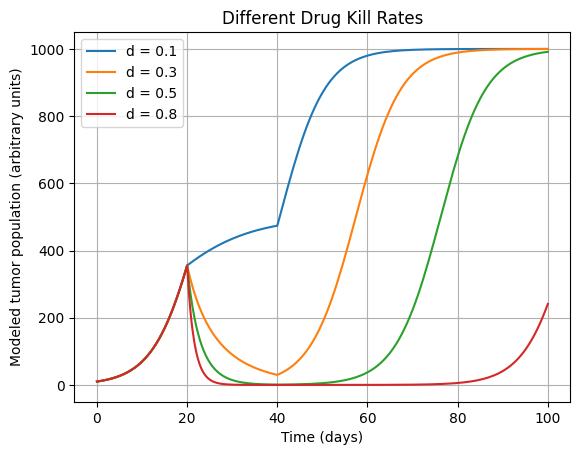

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
drug_kill_rates = [0.1, 0.3, 0.5, 0.8]

for d in drug_kill_rates:
    t, N = simulate_treatment(d)
    plt.plot(t, N, label=f"d = {d}")

plt.xlabel("Time (days)")
plt.ylabel("Modeled tumor population (arbitrary units)")
plt.title("Different Drug Kill Rates")
plt.legend()
plt.grid(True)
plt.show()

Quantitative Analysis of Treatment Response Cell

Tumor populations at the end of treatment (day 40) and the end of the simulation (day 100) are compared across different drug kill rates. The on-treatment equilibrium is calculated to investigate the relationship between intrinsic tumor growth and treatment intensity.

In [10]:
r, K = 0.2, 1000

for d in drug_kill_rates:
    t, N = simulate_treatment(d)
    day_40 = N[t == 40][0]
    equilibrium = f"{K * (1 - d / r):.0f}" if d < r else "none (d >= r: declines)"

    print(f"d={d}: day 40 = {day_40:.2f}, day 100 = {N[-1]:.1f} | "
          f"on-treatment equilibrium: {equilibrium}")

d=0.1: day 40 = 473.92, day 100 = 1000.0 | on-treatment equilibrium: 500
d=0.3: day 40 = 29.79, day 100 = 999.8 | on-treatment equilibrium: none (d >= r: declines)
d=0.5: day 40 = 0.71, day 100 = 991.5 | on-treatment equilibrium: none (d >= r: declines)
d=0.8: day 40 = 0.00, day 100 = 241.2 | on-treatment equilibrium: none (d >= r: declines)


 Single-Course vs. Intermittent Treatment Cell

A continuous treatment course is compared with two separate treatment periods. Both schedules have the same total treatment duration and drug kill rate, allowing the effects of treatment timing on tumor reduction and regrowth to be investigated.

One Course (Days 20–40): min from day 20 = 4.8, day 100 = 998.7
Two Pulses (20–30, 50–60): min from day 20 = 36.8, day 100 = 994.6


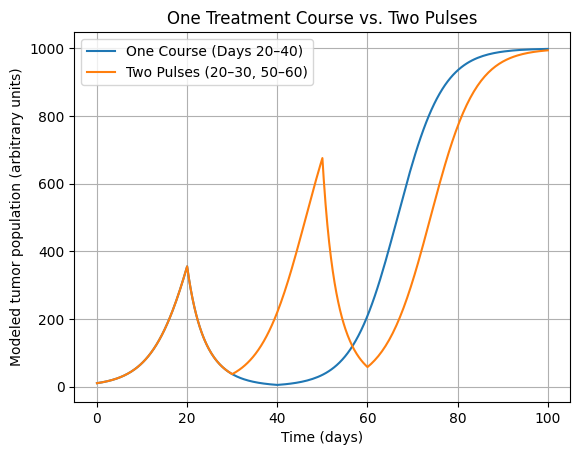

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

def simulate_windows(windows, d=0.4, r=0.2, K=1000, N0=10):
    cuts = {0, 100}
    for start, end in windows:
        cuts.update([start, end])
    cuts = sorted(cuts)

    times, sizes = [], []
    current = N0

    for start, end in zip(cuts, cuts[1:]):
        midpoint = (start + end) / 2
        on_treatment = any(a <= midpoint < b for a, b in windows)
        kill_rate = d if on_treatment else 0

        def rhs(t, N):
            return logistic(t, N, r, K) - kill_rate * N

        sol = solve_ivp(
            rhs, (start, end), [current],
            t_eval=np.linspace(start, end, 101),
            rtol=1e-8, atol=1e-10
        )
        times.extend(sol.t)
        sizes.extend(sol.y[0])
        current = sol.y[0, -1]

    return np.array(times), np.array(sizes)


plans = [
    ("One Course (Days 20–40)", [(20, 40)]),
    ("Two Pulses (20–30, 50–60)", [(20, 30), (50, 60)])
]

for name, windows in plans:
    t, N = simulate_windows(windows)
    plt.plot(t, N, label=name)

    minimum = N[t >= 20].min()
    print(f"{name}: min from day 20 = {minimum:.1f}, day 100 = {N[-1]:.1f}")

plt.xlabel("Time (days)")
plt.ylabel("Modeled tumor population (arbitrary units)")
plt.title("One Treatment Course vs. Two Pulses")
plt.legend()
plt.grid(True)
plt.show()

Parameter Sensitivity Analysis Cell

The intrinsic growth rate and carrying capacity are varied independently to investigate how changes in model parameters influence simulated tumor growth.

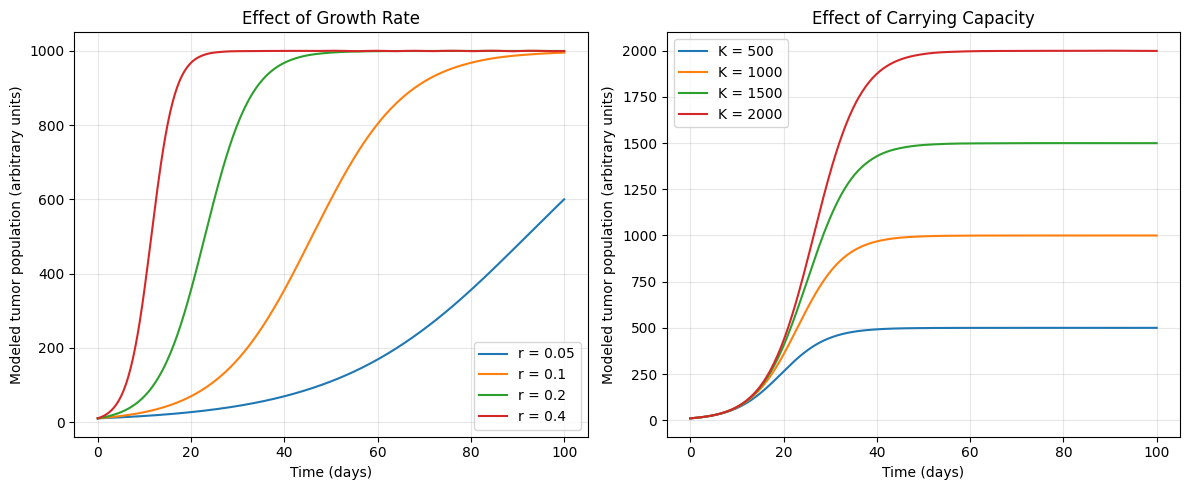

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
t_eval = np.linspace(0, 100, 400)

for r in [0.05, 0.1, 0.2, 0.4]:
    sol = solve_ivp(logistic, (0, 100), [10], args=(r, 1000), t_eval=t_eval)
    axes[0].plot(sol.t, sol.y[0], label=f"r = {r}")

for K in [500, 1000, 1500, 2000]:
    sol = solve_ivp(logistic, (0, 100), [10], args=(0.2, K), t_eval=t_eval)
    axes[1].plot(sol.t, sol.y[0], label=f"K = {K}")

axes[0].set_title("Effect of Growth Rate")
axes[1].set_title("Effect of Carrying Capacity")

for ax in axes:
    ax.set(xlabel="Time (days)", ylabel="Modeled tumor population (arbitrary units)")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Treatment Intensity and Duration Cell

A parameter sweep compares 900 combinations of treatment duration and drug kill rate. A heatmap visualizes the resulting tumor population at day 100.

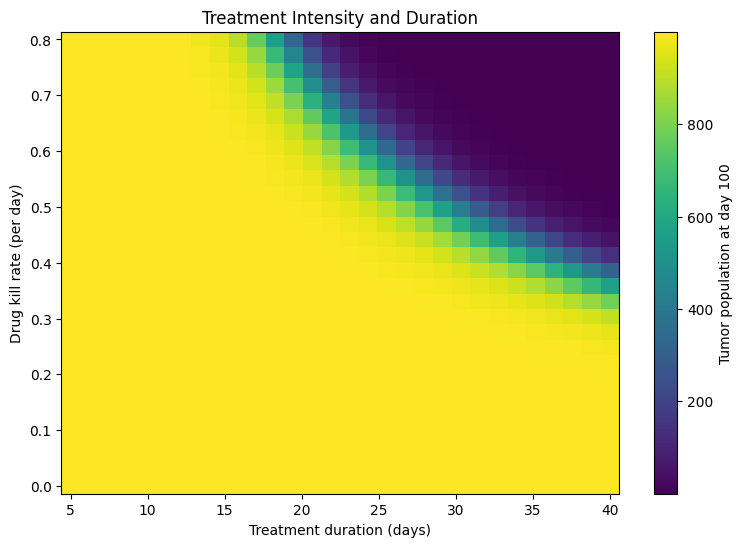

In [13]:
kill_rates = np.linspace(0, 0.8, 30)
durations = np.linspace(5, 40, 30)
results = np.zeros((len(kill_rates), len(durations)))

for i, d in enumerate(kill_rates):
    for j, duration in enumerate(durations):
        _, N = simulate_windows([(20, 20 + duration)], d=d)
        results[i, j] = N[-1]

plt.figure(figsize=(9, 6))
plt.pcolormesh(durations, kill_rates, results, shading="auto", cmap="viridis")
plt.colorbar(label="Tumor population at day 100")
plt.xlabel("Treatment duration (days)")
plt.ylabel("Drug kill rate (per day)")
plt.title("Treatment Intensity and Duration")
plt.show()

Tumor Drug Resistance Cell

The tumor is divided into drug-sensitive and pre-existing drug-resistant populations that compete for shared resources. This model investigates how differences in treatment sensitivity influence tumor composition and regrowth.

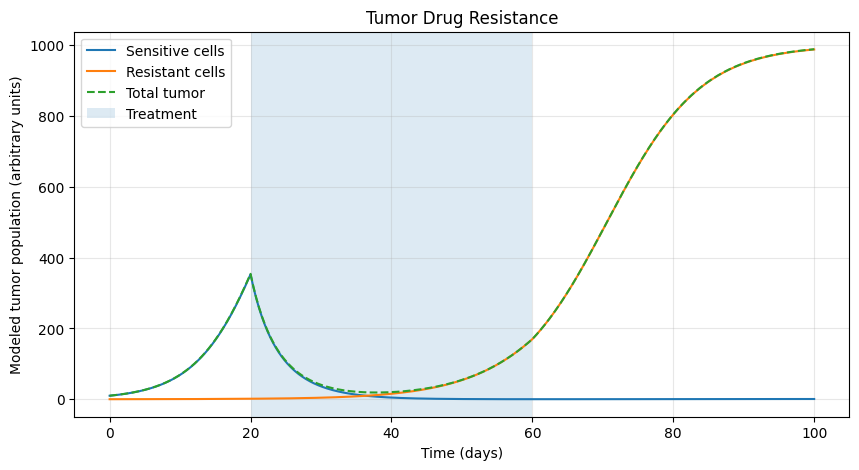

Final tumor population: 988.04
Final resistant percentage: 99.93


In [14]:
def resistance_model(t, y, treatment):
    S, R = y
    competition = 1 - (S + R) / 1000
    dS = 0.4 if treatment else 0
    dR = 0.02 if treatment else 0

    return [
        0.2 * S * competition - dS * S,
        0.15 * R * competition - dR * R
    ]


current = [9.9, 0.1]
times, populations = [], []

for start, end, on in [(0, 20, False), (20, 60, True), (60, 100, False)]:
    sol = solve_ivp(
        resistance_model, (start, end), current,
        args=(on,), t_eval=np.linspace(start, end, 200),
        rtol=1e-8, atol=1e-10
    )
    if not sol.success:
        raise RuntimeError(sol.message)

    times.append(sol.t)
    populations.append(sol.y)
    current = sol.y[:, -1]

times = np.concatenate(times)
S, R = np.concatenate(populations, axis=1)
total = S + R

plt.figure(figsize=(10, 5))
plt.plot(times, S, label="Sensitive cells")
plt.plot(times, R, label="Resistant cells")
plt.plot(times, total, "--", label="Total tumor")
plt.axvspan(20, 60, alpha=0.15, label="Treatment")
plt.xlabel("Time (days)")
plt.ylabel("Modeled tumor population (arbitrary units)")
plt.title("Tumor Drug Resistance")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("Final tumor population:", round(total[-1], 2))
print("Final resistant percentage:", round(100 * R[-1] / total[-1], 2))

## 11. Results and Discussion

### Tumor Growth Models
Increasing the exponential growth rate from 0.2 to 0.4 reduced doubling time from 3.47 to 1.73 days. Logistic and Gompertz models approached a carrying capacity of 1,000 units, with maximum growth rates occurring at population sizes of 500 and approximately 368 units, respectively.

### Numerical Accuracy
Euler's method underestimated the exact exponential growth solution, demonstrating the effect of discretization error.

### Treatment Dynamics
Increasing the drug kill rate from 0.1 to 0.5 reduced the day-40 tumor population from 473.92 to 0.71 units. Single-course treatment achieved a lower minimum population than intermittent treatment (4.8 versus 36.8 units), but intermittent treatment produced a slightly lower day-100 population (994.6 versus 998.7 units).

### Parameter Sensitivity
Higher intrinsic growth rates accelerated tumor growth, while larger carrying capacities increased the long-term population limit.

### Treatment Intensity and Duration
The heatmap compared 900 treatment parameter combinations, illustrating the combined influence of treatment intensity and duration on final tumor burden.

### Drug Resistance
The resistant population increased from 1% to 99.93% of the total tumor population, which reached 988.04 units by day 100. This demonstrates how treatment can select for pre-existing resistant cells within the model.

### Overall Discussion
The simulations highlight the importance of growth kinetics, treatment scheduling, and drug resistance when evaluating tumor reduction and regrowth under simplified mathematical assumptions.

## 12. Limitations

- Model parameters are hypothetical and are not calibrated to clinical data.
- Tumor populations are represented in arbitrary units.
- Treatment effects are represented using simplified drug kill rates.
- The models do not account for immune responses, spatial tumor structure, or treatment toxicity.
- Drug resistance is modeled as a pre-existing population rather than acquired mutations.

These simulations are intended for educational and computational research purposes and should not be interpreted as clinical treatment recommendations.

## 13. Conclusion and Future Directions

This project explores the application of mathematical modeling and computational simulations to tumor growth, treatment dynamics, and drug resistance.

Future extensions could incorporate experimental tumor growth data, drug concentration dynamics, acquired resistance mechanisms, and adaptive treatment strategies.

## 14. References

Benzekry, S., Lamont, C., Beheshti, A., Tracz, A., Ebos, J. M. L., Hlatky, L., & Hahnfeldt, P. (2014). Classical mathematical models for description and prediction of experimental tumor growth. *PLOS Computational Biology, 10*(8), e1003800. https://doi.org/10.1371/journal.pcbi.1003800

Gatenby, R. A., Silva, A. S., Gillies, R. J., & Frieden, B. R. (2009). Adaptive therapy. *Cancer Research, 69*(11), 4894-4903. https://doi.org/10.1158/0008-5472.CAN-08-3658

Mathur, D., Barnett, E., Scher, H. I., & Xavier, J. B. (2022). Optimizing the future: How mathematical models inform treatment schedules for cancer. *Trends in Cancer, 8*(6), 506-516. https://doi.org/10.1016/j.trecan.2022.02.005

#15. Acknowledgments

This project was developed using Python, NumPy, SciPy, Matplotlib, and Google Colab. AI assistance was used to support code development, organization, and documentation.